# Name That LLM 比赛 - Qwen3-4B QLoRA

这个 Notebook 使用 Qwen3-4B-Base 的 4 位量化版本，训练一个 18 分类判别模型。

建议流程：

1. 选择内核 `D:\namellm\.venv\Scripts\python.exe`。
2. 依次运行环境配置和数据单元格。
3. 先用 `epochs = 1` 确认本地链路正常；如果验证集提升，再提高到 2 到 3 轮。
4. 调参时保持 `fold = 0`。单折结果足够好之后，再运行全部 5 折。

训练进度条会显示每次参数更新，每轮结束后会输出验证集指标。

In [1]:
from pathlib import Path
import os
import math
import random
import sys
import time
import warnings

os.environ.setdefault("PYTORCH_CUDA_ALLOC_CONF", "expandable_segments:True")
os.environ.setdefault("TRANSFORMERS_VERBOSITY", "error")
os.environ.setdefault("HF_HUB_DISABLE_PROGRESS_BARS", "1")
warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import torch
import matplotlib.pyplot as plt
from IPython.display import clear_output, display
from sklearn.metrics import balanced_accuracy_score, confusion_matrix
from sklearn.model_selection import GroupKFold
from torch.utils.data import DataLoader, Dataset
from transformers import (
    AutoModelForSequenceClassification,
    AutoTokenizer,
    BitsAndBytesConfig,
    get_linear_schedule_with_warmup,
)
from peft import LoraConfig, get_peft_model, prepare_model_for_kbit_training
from transformers.utils import logging as transformers_logging

transformers_logging.set_verbosity_error()
transformers_logging.disable_progress_bar()

plt.rcParams["font.sans-serif"] = ["Microsoft YaHei", "SimHei", "Arial Unicode MS"]
plt.rcParams["axes.unicode_minus"] = False

ROOT = Path.cwd()
if not (ROOT / "data/raw/train.csv").exists():
    ROOT = ROOT.parent
sys.path.insert(0, str(ROOT / "src"))

from namellm.constants import LABELS

CONFIG = {
    "model_dir": ROOT / "models/Qwen3-4B-Base",
    "fold": 0,
    "epochs": 1,
    "max_steps": 0,
    "max_length": 256,
    "batch_size": 2,
    "grad_accum": 4,
    "learning_rate": 2e-4,
    "validation_limit": 0,
    "plot_every": 5,
    "seed": 42,
    "lora_rank": 8,
    "lora_alpha": 16,
    "output_dir": ROOT / "artifacts/qlora_fold0",
}

random.seed(CONFIG["seed"])
np.random.seed(CONFIG["seed"])
torch.manual_seed(CONFIG["seed"])
torch.cuda.manual_seed_all(CONFIG["seed"])

assert torch.cuda.is_available(), "4 位 QLoRA 需要可用的 CUDA 显卡"
assert CONFIG["model_dir"].exists(), f"找不到模型目录：{CONFIG['model_dir']}"
训练摘要 = pd.DataFrame(
    {
        "显卡": [torch.cuda.get_device_name(0)],
        "训练折": [CONFIG["fold"]],
        "训练轮数": [CONFIG["epochs"]],
        "最大长度": [CONFIG["max_length"]],
        "批大小": [CONFIG["batch_size"]],
        "梯度累积": [CONFIG["grad_accum"]],
        "学习率": [CONFIG["learning_rate"]],
    }
)

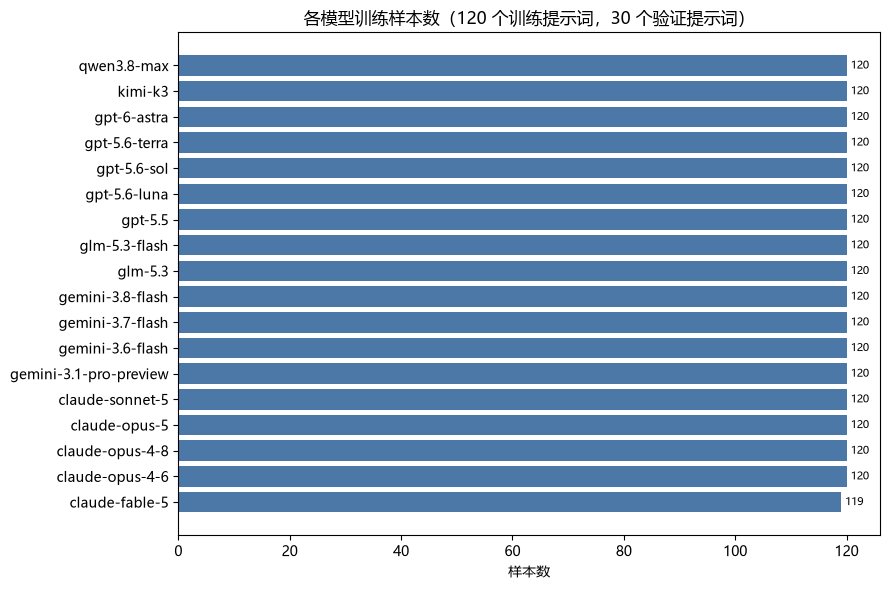

In [2]:
frame = pd.read_csv(ROOT / "data/raw/train.csv")
label_to_index = {label: index for index, label in enumerate(LABELS)}
labels = np.array([label_to_index[value] for value in frame["model"]])

folds = list(GroupKFold(5).split(frame, labels, frame["prompt_id"]))
train_idx, valid_idx = folds[CONFIG["fold"]]
if CONFIG["validation_limit"]:
    valid_idx = valid_idx[: CONFIG["validation_limit"]]

train_prompts = frame["prompt_id"].iloc[train_idx].nunique()
valid_prompts = frame["prompt_id"].iloc[valid_idx].nunique()
overlap = set(frame["prompt_id"].iloc[train_idx]) & set(frame["prompt_id"].iloc[valid_idx])
assert not overlap, "检测到提示词泄漏"

样本分布 = (
    frame.iloc[train_idx]
    .groupby("model")
    .size()
    .reindex(LABELS)
    .rename("训练样本数")
    .to_frame()
)
fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(样本分布.index, 样本分布["训练样本数"], color="#4c78a8")
ax.bar_label(bars, padding=3, fontsize=8)
ax.set_title(f"各模型训练样本数（{train_prompts} 个训练提示词，{valid_prompts} 个验证提示词）")
ax.set_xlabel("样本数")
plt.tight_layout()
plt.show()

In [3]:
tokenizer = AutoTokenizer.from_pretrained(CONFIG["model_dir"])
tokenizer.padding_side = "right"
if tokenizer.pad_token_id is None:
    tokenizer.pad_token = tokenizer.eos_token


class TextRows(Dataset):
    def __init__(self, indices):
        self.indices = list(indices)

    def __len__(self):
        return len(self.indices)

    def __getitem__(self, item):
        row = self.indices[item]
        return {"text": frame["text"].iloc[row], "label": int(labels[row])}


def collate(items):
    encoded = tokenizer(
        [item["text"] for item in items],
        padding=True,
        truncation=True,
        max_length=CONFIG["max_length"],
        return_tensors="pt",
    )
    encoded["labels"] = torch.tensor([item["label"] for item in items])
    return encoded


train_loader = DataLoader(
    TextRows(train_idx),
    batch_size=CONFIG["batch_size"],
    shuffle=True,
    collate_fn=collate,
    num_workers=0,
)
valid_loader = DataLoader(
    TextRows(valid_idx),
    batch_size=CONFIG["batch_size"] * 2,
    shuffle=False,
    collate_fn=collate,
    num_workers=0,
)

In [4]:
device = torch.device("cuda")
quantization_config = BitsAndBytesConfig(
    load_in_4bit=True,
    bnb_4bit_compute_dtype=torch.bfloat16,
    bnb_4bit_quant_type="nf4",
    bnb_4bit_use_double_quant=True,
)

model = AutoModelForSequenceClassification.from_pretrained(
    CONFIG["model_dir"],
    num_labels=len(LABELS),
    quantization_config=quantization_config,
    device_map={"": device.index or 0},
)
model.config.pad_token_id = tokenizer.pad_token_id
model.config.use_cache = False
model = prepare_model_for_kbit_training(model, use_gradient_checkpointing=True)

lora_config = LoraConfig(
    r=CONFIG["lora_rank"],
    lora_alpha=CONFIG["lora_alpha"],
    lora_dropout=0.05,
    bias="none",
    task_type="SEQ_CLS",
    target_modules=["q_proj", "k_proj", "v_proj"],
    modules_to_save=["score"],
)
model = get_peft_model(model, lora_config)
可训练参数 = sum(parameter.numel() for parameter in model.parameters() if parameter.requires_grad)
全部参数 = sum(parameter.numel() for parameter in model.parameters())
model.train()

W1115 16:08:32.049000 26500 Lib\site-packages\torch\utils\flop_counter.py:29] triton not found; flop counting will not work for triton kernels


PeftModelForSequenceClassification(
  (base_model): LoraModel(
    (model): Qwen3ForSequenceClassification(
      (model): Qwen3Model(
        (embed_tokens): Embedding(151936, 2560)
        (layers): ModuleList(
          (0-35): 36 x Qwen3DecoderLayer(
            (self_attn): Qwen3Attention(
              (q_proj): lora.Linear4bit(
                (base_layer): Linear4bit(in_features=2560, out_features=4096, bias=False)
                (lora_dropout): ModuleDict(
                  (default): Dropout(p=0.05, inplace=False)
                )
                (lora_A): ModuleDict(
                  (default): Linear(in_features=2560, out_features=8, bias=False)
                )
                (lora_B): ModuleDict(
                  (default): Linear(in_features=8, out_features=4096, bias=False)
                )
                (lora_embedding_A): ParameterDict()
                (lora_embedding_B): ParameterDict()
                (lora_magnitude_vector): ModuleDict()
              )
 

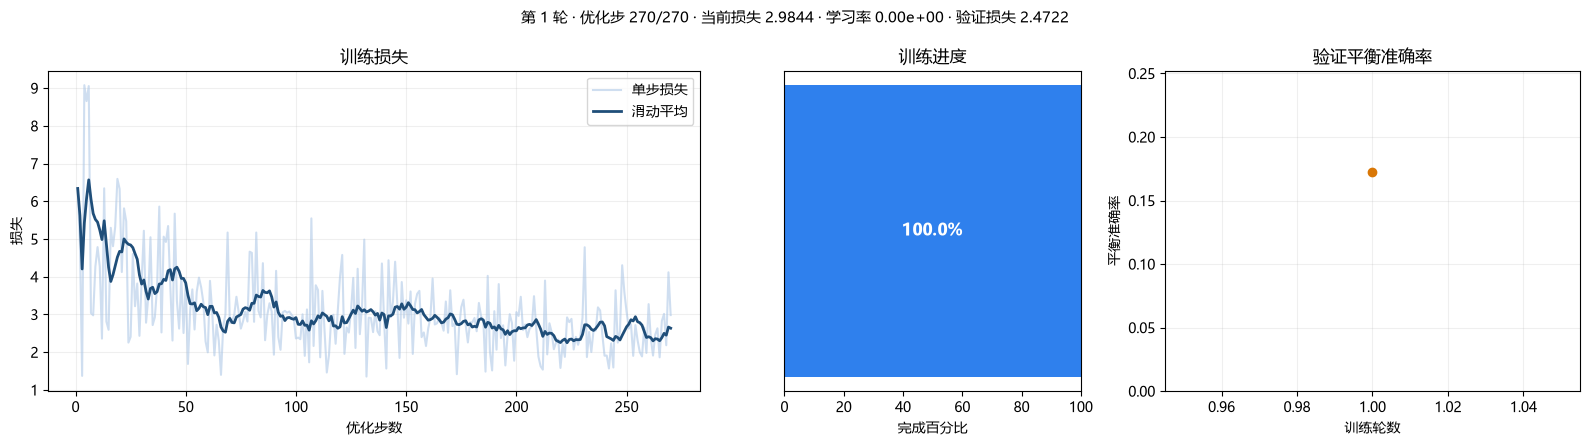

In [5]:
def evaluate_model(loader):
    model.eval()
    losses = []
    predictions = []
    targets = []
    probabilities = []
    with torch.inference_mode():
        for batch in loader:
            batch_labels = batch.pop("labels")
            batch = {name: value.to(device) for name, value in batch.items()}
            output = model(**batch, labels=batch_labels.to(device))
            losses.append(float(output.loss))
            probabilities.append(torch.softmax(output.logits.float(), dim=-1).cpu())
            predictions.extend(output.logits.float().argmax(dim=-1).cpu().tolist())
            targets.extend(batch_labels.tolist())
    probability_array = torch.cat(probabilities).numpy()
    score = balanced_accuracy_score(targets, predictions)
    return float(np.mean(losses)), score, np.array(targets), np.array(predictions), probability_array


def draw_training_dashboard(当前轮, 当前步, 总步数, 当前损失, 当前学习率, 当前验证损失=None):
    clear_output(wait=True)
    fig, axes = plt.subplots(
        1,
        3,
        figsize=(16, 4.5),
        gridspec_kw={"width_ratios": [2.2, 1.0, 1.4]},
    )

    if history["step_loss"]:
        losses = pd.Series(history["step_loss"])
        axes[0].plot(history["step"], losses, color="#a8c4e5", alpha=0.55, label="单步损失")
        axes[0].plot(
            history["step"],
            losses.rolling(10, min_periods=1).mean(),
            color="#1f4e79",
            linewidth=2,
            label="滑动平均",
        )
        axes[0].legend(loc="upper right")
    axes[0].set_title("训练损失")
    axes[0].set_xlabel("优化步数")
    axes[0].set_ylabel("损失")
    axes[0].grid(alpha=0.2)

    完成百分比 = np.clip(当前步 / max(总步数, 1) * 100, 0, 100)
    axes[1].barh([0], [100], color="#e5e7eb", height=0.5)
    axes[1].barh([0], [完成百分比], color="#2f80ed", height=0.5)
    axes[1].set_xlim(0, 100)
    axes[1].set_yticks([])
    axes[1].set_xlabel("完成百分比")
    axes[1].set_title("训练进度")
    axes[1].text(
        完成百分比 / 2,
        0,
        f"{完成百分比:.1f}%",
        ha="center",
        va="center",
        color="white" if 完成百分比 > 18 else "#1f2937",
        fontsize=12,
        fontweight="bold",
    )

    if history["epoch"]:
        axes[2].plot(history["epoch"], history["valid_bacc"], marker="o", color="#d97706")
        axes[2].set_ylim(0, max(0.2, min(1.0, max(history["valid_bacc"]) + 0.08)))
        axes[2].grid(alpha=0.2)
    else:
        axes[2].text(0.5, 0.5, "首轮验证尚未完成", ha="center", va="center")
        axes[2].set_xlim(0, 1)
        axes[2].set_ylim(0, 1)
    axes[2].set_title("验证平衡准确率")
    axes[2].set_xlabel("训练轮数")
    axes[2].set_ylabel("平衡准确率")

    标题 = (
        f"第 {当前轮} 轮 · 优化步 {当前步}/{总步数} · "
        f"当前损失 {当前损失:.4f} · 学习率 {当前学习率:.2e}"
    )
    if 当前验证损失 is not None:
        标题 += f" · 验证损失 {当前验证损失:.4f}"
    fig.suptitle(标题, fontsize=11)
    plt.tight_layout()
    display(fig)
    plt.close(fig)


trainable = [parameter for parameter in model.parameters() if parameter.requires_grad]
optimizer = torch.optim.AdamW(trainable, lr=CONFIG["learning_rate"], weight_decay=0.01)
updates_per_epoch = math.ceil(len(train_loader) / CONFIG["grad_accum"])
total_steps = CONFIG["max_steps"] or int(updates_per_epoch * CONFIG["epochs"])
scheduler = get_linear_schedule_with_warmup(
    optimizer,
    num_warmup_steps=max(1, int(total_steps * 0.05)),
    num_training_steps=total_steps,
)

history = {"step": [], "step_loss": [], "epoch": [], "valid_loss": [], "valid_bacc": []}
completed_steps = 0
last_eval_step = -1
started = time.time()

for epoch in range(1, math.ceil(CONFIG["epochs"]) + 1):
    model.train()
    optimizer.zero_grad(set_to_none=True)
    for batch_index, batch in enumerate(train_loader, start=1):
        batch_labels = batch.pop("labels")
        batch = {name: value.to(device) for name, value in batch.items()}
        with torch.autocast("cuda", dtype=torch.bfloat16):
            output = model(**batch, labels=batch_labels.to(device))
            loss = output.loss / CONFIG["grad_accum"]
        loss.backward()

        if batch_index % CONFIG["grad_accum"] == 0:
            torch.nn.utils.clip_grad_norm_(trainable, 1.0)
            optimizer.step()
            scheduler.step()
            optimizer.zero_grad(set_to_none=True)
            completed_steps += 1
            history["step"].append(completed_steps)
            history["step_loss"].append(float(loss.detach()) * CONFIG["grad_accum"])
            if completed_steps % CONFIG["plot_every"] == 0 or completed_steps == 1:
                draw_training_dashboard(
                    epoch,
                    completed_steps,
                    total_steps,
                    history["step_loss"][-1],
                    scheduler.get_last_lr()[0],
                )
            if CONFIG["max_steps"] and completed_steps >= CONFIG["max_steps"]:
                break

    valid_loss, valid_score, y_true, y_pred, valid_prob = evaluate_model(valid_loader)
    last_eval_step = completed_steps
    history["epoch"].append(epoch)
    history["valid_loss"].append(valid_loss)
    history["valid_bacc"].append(valid_score)
    draw_training_dashboard(
        epoch,
        completed_steps,
        total_steps,
        history["step_loss"][-1],
        scheduler.get_last_lr()[0],
        valid_loss,
    )
    if CONFIG["max_steps"] and completed_steps >= CONFIG["max_steps"]:
        break

if last_eval_step != completed_steps:
    valid_loss, valid_score, y_true, y_pred, valid_prob = evaluate_model(valid_loader)
    draw_training_dashboard(
        epoch,
        completed_steps,
        total_steps,
        history["step_loss"][-1],
        scheduler.get_last_lr()[0],
        valid_loss,
    )


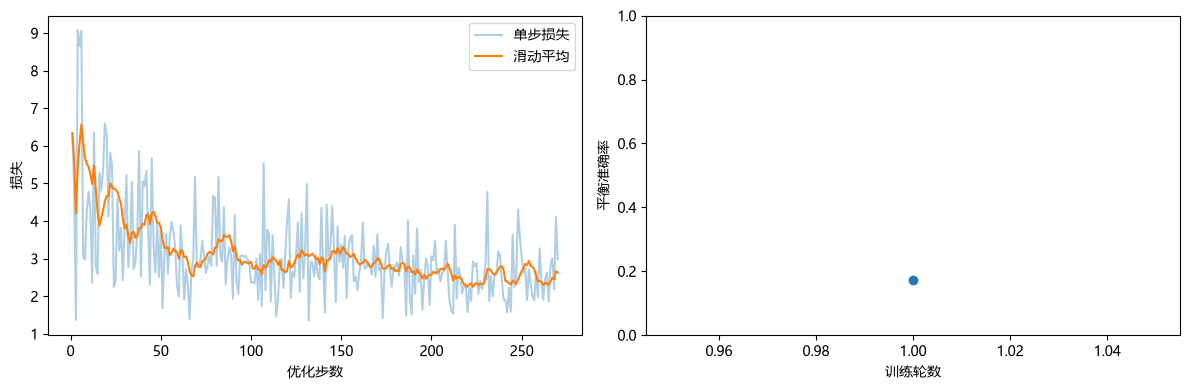

In [6]:
%matplotlib inline
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

if history["step_loss"]:
    losses = pd.Series(history["step_loss"])
    axes[0].plot(history["step"], losses, alpha=0.35, label="单步损失")
    axes[0].plot(history["step"], losses.rolling(10, min_periods=1).mean(), label="滑动平均")
    axes[0].set_xlabel("优化步数")
    axes[0].set_ylabel("损失")
    axes[0].legend()

if history["epoch"]:
    axes[1].plot(history["epoch"], history["valid_bacc"], marker="o")
    axes[1].set_xlabel("训练轮数")
    axes[1].set_ylabel("平衡准确率")
    axes[1].set_ylim(0, 1)

plt.tight_layout()
plt.show()

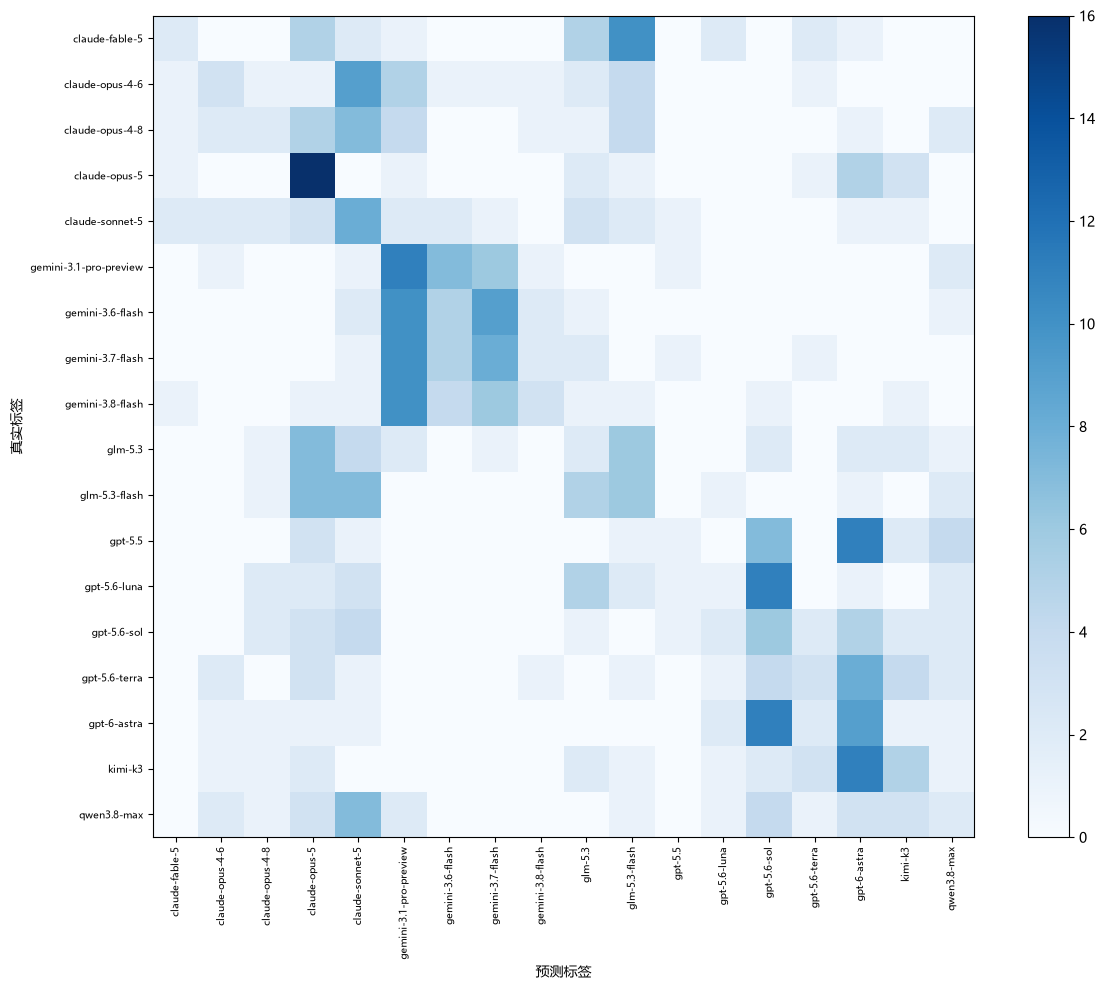

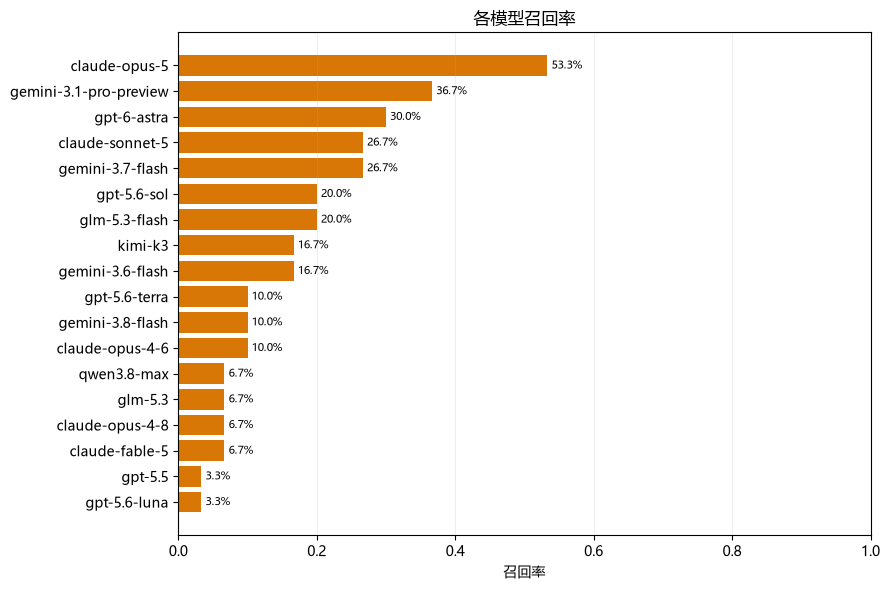

In [7]:
%matplotlib inline
matrix = confusion_matrix(y_true, y_pred, labels=np.arange(len(LABELS)))
fig, ax = plt.subplots(figsize=(12, 10))
image = ax.imshow(matrix, cmap="Blues")
ax.set_xticks(np.arange(len(LABELS)), LABELS, rotation=90, fontsize=7)
ax.set_yticks(np.arange(len(LABELS)), LABELS, fontsize=7)
ax.set_xlabel("预测标签")
ax.set_ylabel("真实标签")
fig.colorbar(image, ax=ax, fraction=0.046)
plt.tight_layout()
plt.show()

per_class = pd.Series(
    [(y_pred[y_true == index] == index).mean() for index in range(len(LABELS))],
    index=LABELS,
    name="召回率",
).sort_values()
fig, ax = plt.subplots(figsize=(9, 6))
bars = ax.barh(per_class.index, per_class.values, color="#d97706")
ax.bar_label(bars, labels=[f"{value:.1%}" for value in per_class.values], padding=3, fontsize=8)
ax.set_xlim(0, 1)
ax.set_title("各模型召回率")
ax.set_xlabel("召回率")
ax.grid(axis="x", alpha=0.2)
plt.tight_layout()
plt.show()

In [ ]:
CONFIG["output_dir"].mkdir(parents=True, exist_ok=True)
model.save_pretrained(CONFIG["output_dir"])
tokenizer.save_pretrained(CONFIG["output_dir"])
np.save(CONFIG["output_dir"] / "valid_probabilities.npy", valid_prob)
np.save(CONFIG["output_dir"] / "valid_targets.npy", y_true)
np.save(CONFIG["output_dir"] / "valid_predictions.npy", y_pred)
pd.DataFrame(history).to_csv(CONFIG["output_dir"] / "history.csv", index=False)

# 按项目统一的标签顺序保存可直接用于融合的 OOF 概率文件。
oof_frame = pd.DataFrame(valid_prob, columns=LABELS)
oof_frame.insert(0, "row_index", valid_idx)
oof_frame.to_parquet(ROOT / f"features/qlora_fold{CONFIG['fold']}_oof.parquet", index=False)

PermissionError: [WinError 5] 拒绝访问。: 'd:\\namellm\\artifacts'

: 

## 后续步骤

- 如果验证集平衡准确率随训练轮数持续提升，就保留最佳 adapter，并运行其余折。
- 使用按提示词分组的 OOF 验证结果，将 QLoRA 概率与 `D:/tmp/namellm_funnel/funnel.npy` 融合。
- 最终隐藏测试预测不要使用逐提示词的匈牙利配额分配，因为测试集的类别比例不保证相等。
- 当前完整特征漏斗的 OOF 约为 0.47。只有当 QLoRA 在未见提示词上明显超过该分数时，才应替换或融合它。